# Student Performance — Machine Learning

A compact end-to-end notebook: load, explore, visualize, train, test, evaluate, and save a model.

Put `xAPI-Edu-Data.csv` beside this notebook or in a `data/` folder. The target column should be `Class` with labels `L`, `M`, and `H`. If the file has another name, the notebook uses it when it is the only CSV in the folder.

*Demographic columns (gender, nationality, and birthplace) are excluded from training.*


## 1. Load data

Required packages: `pandas`, `scikit-learn`, `matplotlib`, and `joblib`. If needed, run `%pip install pandas scikit-learn matplotlib joblib` in a notebook cell.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

preferred_paths = [
    Path("xAPI-Edu-Data.csv"),
    Path("data/xAPI-Edu-Data.csv"),
]
DATA_PATH = next((path for path in preferred_paths if path.exists()), None)

if DATA_PATH is None:
    folders = [Path.cwd(), Path.cwd() / "data"]
    csv_files = sorted({path for folder in folders if folder.exists() for path in folder.glob("*.csv")
                        if path.name.lower() != "sample_input.csv"})
    named = [path for path in csv_files if "xapi" in path.name.lower() or "edu" in path.name.lower()]
    if len(named) == 1:
        DATA_PATH = named[0]
    elif len(csv_files) == 1:
        DATA_PATH = csv_files[0]
    else:
        raise FileNotFoundError(
            "Add xAPI-Edu-Data.csv beside this notebook or inside data/. "
            "If your data uses another filename, set DATA_PATH to its path."
        )

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.astype(str).str.strip()
for column in df.select_dtypes(include=["object", "string"]).columns:
    df[column] = df[column].map(lambda value: value.strip() if isinstance(value, str) else value)

target_candidates = [column for column in df.columns if column.lower() == "class"]
if not target_candidates:
    raise ValueError("The dataset must contain a target column named 'Class'.")
TARGET = target_candidates[0]
if TARGET != "Class":
    df = df.rename(columns={TARGET: "Class"})
TARGET = "Class"
df[TARGET] = df[TARGET].astype("string").str.strip().str.upper()
df = df[df[TARGET].isin(["L", "M", "H"])].copy()

print(f"Dataset: {DATA_PATH}")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


Dataset: data\xAPI-Edu-Data.csv
Rows: 480 | Columns: 17


## 2. Inspect and visualize


In [2]:
print("Missing values by column:")
display(df.isna().sum().rename("missing values").to_frame())
print("Class counts:")
display(df["Class"].value_counts().reindex(["L", "M", "H"], fill_value=0).rename_axis("Class").to_frame("Students"))


,missing values
gender,0
NationalITy,0
PlaceofBirth,0
StageID,0
GradeID,0
SectionID,0
Topic,0
Semester,0
Relation,0
raisedhands,0


,Students
Class,
L,127
M,211
H,142


Missing values by column:
Class counts:


<cell 3>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


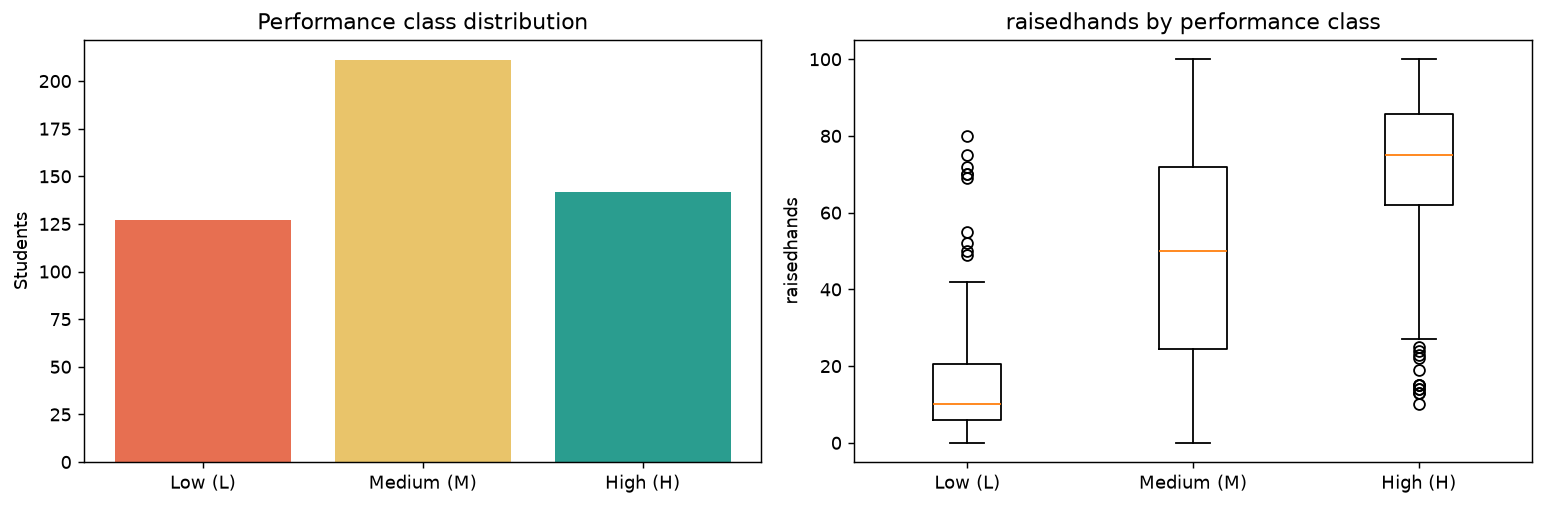

In [3]:
engagement = [name for name in ["raisedhands", "VisITedResources", "AnnouncementsView", "Discussion"]
              if name in df.columns]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts = df["Class"].value_counts().reindex(["L", "M", "H"], fill_value=0)
axes[0].bar(["Low (L)", "Medium (M)", "High (H)"], counts.values, color=["#e76f51", "#e9c46a", "#2a9d8f"])
axes[0].set_title("Performance class distribution")
axes[0].set_ylabel("Students")

if engagement:
    feature = engagement[0]
    groups = [df.loc[df["Class"] == label, feature].dropna().values for label in ["L", "M", "H"]]
    axes[1].boxplot(groups)
    axes[1].set_xticks([1, 2, 3])
    axes[1].set_xticklabels(["Low (L)", "Medium (M)", "High (H)"])
    axes[1].set_title(f"{feature} by performance class")
    axes[1].set_ylabel(feature)
else:
    axes[1].axis("off")
    axes[1].text(0.5, 0.5, "No engagement feature found", ha="center", va="center")

plt.tight_layout()
plt.show()


## 3. Prepare features and split train/test data


In [4]:
audit_names = {"gender", "nationality", "nationality", "placeofbirth"}
audit_columns = [column for column in df.columns if column.lower() in audit_names]
feature_columns = [column for column in df.columns if column != TARGET and column not in audit_columns]

X = df[feature_columns].copy()
y = df[TARGET].copy()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [column for column in X.columns if column not in numeric_features]

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError("Each performance class needs at least two rows for a stratified train/test split.")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Features: {len(feature_columns)} | Numeric: {len(numeric_features)} | Categorical: {len(categorical_features)}")
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Excluded demographic columns: {audit_columns or 'None found'}")


Features: 13 | Numeric: 4 | Categorical: 9
Train rows: 384 | Test rows: 96
Excluded demographic columns: ['gender', 'NationalITy', 'PlaceofBirth']


## 4. Train a model


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

transformers = []
if numeric_features:
    transformers.append(("numeric", SimpleImputer(strategy="median"), numeric_features))
if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ])
    transformers.append(("categorical", categorical_pipeline, categorical_features))

preprocess = ColumnTransformer(transformers=transformers, remainder="drop")
model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=42, n_jobs=-1,
    )),
])

folds = min(5, int(y_train.value_counts().min()))
if folds >= 2:
    cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1)
    print(f"{folds}-fold CV macro F1: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
else:
    print("Cross-validation skipped: a class has too few training rows.")

model.fit(X_train, y_train)
print("Training complete.")


5-fold CV macro F1: 0.779 ± 0.062
Training complete.


## 5. Test and evaluate


In [6]:
from sklearn.metrics import accuracy_score, classification_report, f1_score

y_pred = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test macro F1: {f1_score(y_test, y_pred, average='macro'):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=[label for label in ["L", "M", "H"] if label in y.unique()], zero_division=0))


Test accuracy: 0.708
Test macro F1: 0.719

Classification report:
              precision    recall  f1-score   support

           L       0.78      0.84      0.81        25
           M       0.68      0.62      0.65        42
           H       0.68      0.72      0.70        29

    accuracy                           0.71        96
   macro avg       0.71      0.73      0.72        96
weighted avg       0.71      0.71      0.71        96



<cell 7>:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


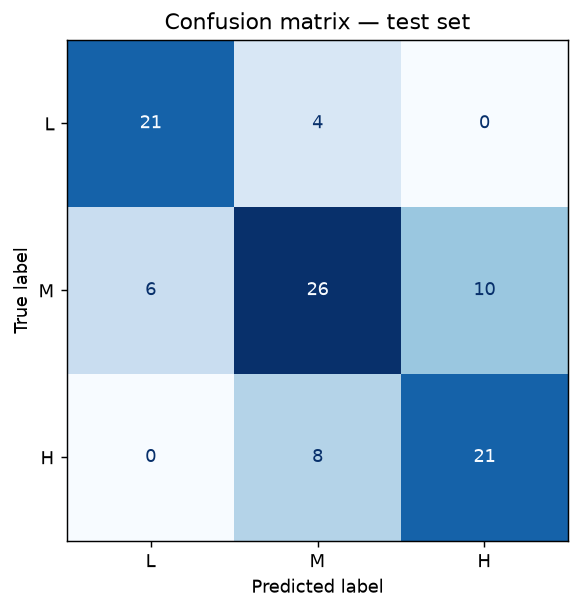

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = [label for label in ["L", "M", "H"] if label in y.unique()]
matrix = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(matrix, display_labels=labels).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix — test set")
plt.tight_layout()
plt.show()


## 6. Inspect feature importance and save the model


,feature,importance
0,numeric__VisITedResources,0.156460
1,numeric__raisedhands,0.146560
2,categorical__StudentAbsenceDays_Under-7,0.118670
3,categorical__StudentAbsenceDays_Above-7,0.102293
4,numeric__AnnouncementsView,0.095459
5,numeric__Discussion,0.063838
6,categorical__Relation_Father,0.034553
7,categorical__ParentAnsweringSurvey_Yes,0.033108
8,categorical__Relation_Mum,0.032777
9,categorical__ParentAnsweringSurvey_No,0.031780


<cell 8>:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


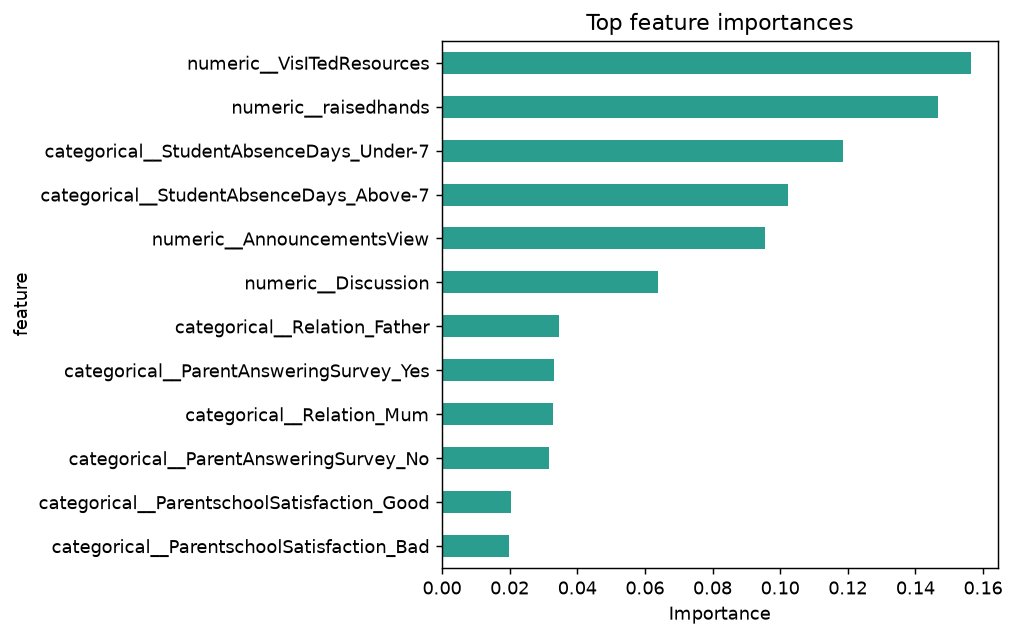

In [8]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_
importance = pd.DataFrame({"feature": feature_names, "importance": importances})
importance = importance.sort_values("importance", ascending=False).head(12)
display(importance.reset_index(drop=True))

importance.sort_values("importance").plot.barh(
    x="feature", y="importance", legend=False, figsize=(8, 5), color="#2a9d8f"
)
plt.title("Top feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [9]:
MODEL_PATH = Path("student_performance_model.joblib")
joblib.dump(model, MODEL_PATH)
print(f"Saved trained model to: {MODEL_PATH}")

example = X_test.iloc[[0]]
print(f"Example prediction: {model.predict(example)[0]} | Actual: {y_test.iloc[0]}")


Saved trained model to: student_performance_model.joblib
Example prediction: H | Actual: M


## Done

The saved file contains the full preprocessing-and-model pipeline. The dataset is small and context-specific; use predictions only as an initial signal for supportive human review, not as an automated decision.
